In [2]:

# Step 1: Install the UCI dataset library
!pip -q install ucimlrepo

# Step 2: Import the required library
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Step 3: Fetch the official UCI dataset (ID 891)
cdc = fetch_ucirepo(id=891)

# Step 4: Combine the features and target
X = cdc.data.features
y = cdc.data.targets

df = pd.concat([X, y], axis=1)

# Step 5: Check the dataset
print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Step 6: Preview the first five rows
df.head()

Dataset downloaded successfully!
Dataset shape: (253680, 22)

Column names:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'Diabetes_binary']


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [3]:

# Count records in each target class
print("Target counts:")
print(df["Diabetes_binary"].value_counts().sort_index())

# Calculate class percentages
print("\nTarget percentages:")
print(
    (df["Diabetes_binary"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Target counts:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Target percentages:
Diabetes_binary
0    86.07
1    13.93
Name: proportion, dtype: float64


In [4]:

# 1. Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# 2. Calculate the total number of missing cells
print("\nTotal missing cells:", df.isnull().sum().sum())

# 3. Check column data types
print("\nColumn data types:")
print(df.dtypes)

# 4. Check dataset dimensions
print("\nDataset dimensions:", df.shape)

Missing values per column:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64

Total missing cells: 0

Column data types:
HighBP                  int64
HighChol                int64
CholCheck               int64
BMI                     int64
Smoker                  int64
Stroke                  int64
HeartDiseaseorAttack    int64
PhysActivity            int64
Fruits                  int64
Veggies                 int64
HvyAlcoholConsump       int64
AnyHealthcare 

In [5]:

# Statistical summary of all 22 columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0


In [6]:

# Check exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print(
    "Percentage of duplicate rows:",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)

Number of duplicate rows: 24206
Percentage of duplicate rows: 9.54 %


In [7]:

# Count exact duplicates separately by target class
duplicate_mask = df.duplicated()

print("Duplicate rows by target class:")
print(df.loc[duplicate_mask, "Diabetes_binary"].value_counts().sort_index())

print("\nTarget distribution in the complete dataset:")
print(df["Diabetes_binary"].value_counts().sort_index())

Duplicate rows by target class:
Diabetes_binary
0    23957
1      249
Name: count, dtype: int64

Target distribution in the complete dataset:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64


## 1. Dataset Loading and Duplicate Record Identification

The CDC Diabetes Health Indicators dataset was obtained from the UCI Machine Learning Repository using the `ucimlrepo` Python library (Dataset ID: 891).

The dataset contains 253,680 records and 22 columns, consisting of 21 input features and one target variable (`Diabetes_binary`). The target variable represents whether a record belongs to the non-diabetes category (0) or the combined prediabetes/diabetes category (1).

During the initial exploratory data analysis, the target distribution and duplicate records were examined.

The original dataset contained 218,334 records in Class 0 (86.07%) and 35,346 records in Class 1 (13.93%).

A duplicate-record check using Pandas identified 24,206 duplicate rows, representing approximately 9.54% of the dataset. A further examination showed that 23,957 duplicate rows belonged to Class 0 and 249 belonged to Class 1.

In the original experiment, these duplicate records were identified and counted but were not removed before model training. This revised experiment investigates the effect of removing exact duplicate rows and repeating the model evaluation.

In [8]:
# Create a new dataset after removing exact duplicate rows
df_clean = df.drop_duplicates().copy()

# Compare original and revised dataset sizes
print("Original dataset shape:", df.shape)
print("Dataset shape after removing duplicates:", df_clean.shape)

# Verify duplicate removal
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Original dataset shape: (253680, 22)
Dataset shape after removing duplicates: (229474, 22)
Remaining duplicate rows: 0


## 2. Duplicate Record Removal

A separate copy of the original dataset was created for the revised experiment. The Pandas `drop_duplicates()` function was applied to remove exact duplicate rows while retaining the first occurrence of each unique row.

The original dataset contained 253,680 records and 22 columns. After removing 24,206 duplicate rows, the revised dataset contained 229,474 records and 22 columns.

The duplicate check was performed again after removal and returned zero remaining duplicate rows.

The original DataFrame was preserved so that the revised experiment could be compared with the initial model results.

In [9]:
# Count target classes after duplicate removal
print("Target counts after duplicate removal:")
print(df_clean["Diabetes_binary"].value_counts().sort_index())

# Calculate target percentages
print("\nTarget percentages after duplicate removal:")
print(
    (df_clean["Diabetes_binary"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Target counts after duplicate removal:
Diabetes_binary
0    194377
1     35097
Name: count, dtype: int64

Target percentages after duplicate removal:
Diabetes_binary
0    84.71
1    15.29
Name: proportion, dtype: float64


## 3. Target Distribution After Duplicate Removal

After removing exact duplicate rows, the target class distribution was examined again to understand the effect of duplicate removal on the dataset.

The revised dataset contained 194,377 records in Class 0 (84.71%) and 35,097 records in Class 1 (15.29%). In comparison, the original dataset contained 86.07% Class 0 records and 13.93% Class 1 records.

The proportion of Class 1 increased from 13.93% to 15.29% because a considerably larger number of duplicate rows belonged to Class 0.

Although the class distribution changed, the revised dataset remained imbalanced. This difference will be considered when comparing the performance of the machine learning models in the two experiments.

In [10]:
# Separate input features and target variable
X_clean = df_clean.drop("Diabetes_binary", axis=1)
y_clean = df_clean["Diabetes_binary"]

# Check dimensions
print("Features shape:", X_clean.shape)
print("Target shape:", y_clean.shape)

Features shape: (229474, 21)
Target shape: (229474,)


## 5. Train-Test Split

The revised dataset was divided into training and testing sets using an 80:20 ratio. The training set was used to train the machine learning models, while the testing set was reserved for evaluating their performance on unseen records.

Stratified sampling was used to maintain approximately the same proportion of Class 0 and Class 1 records in both sets. This was important because the target variable remained imbalanced even after duplicate removal.

In [11]:
# Import the train-test split function
from sklearn.model_selection import train_test_split

# Split the revised dataset
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

# Check the shapes
print("Training features:", X_train_clean.shape)
print("Testing features:", X_test_clean.shape)
print("Training target:", y_train_clean.shape)
print("Testing target:", y_test_clean.shape)

Training features: (183579, 21)
Testing features: (45895, 21)
Training target: (183579,)
Testing target: (45895,)


In [12]:
# Check class distribution in training data
print("Training target distribution:")
print(y_train_clean.value_counts(normalize=True).sort_index() * 100)

# Check class distribution in testing data
print("\nTesting target distribution:")
print(y_test_clean.value_counts(normalize=True).sort_index() * 100)

Training target distribution:
Diabetes_binary
0    84.705222
1    15.294778
Name: proportion, dtype: float64

Testing target distribution:
Diabetes_binary
0    84.706395
1    15.293605
Name: proportion, dtype: float64


The class distribution was verified after the train-test split. The training set contained approximately 84.71% Class 0 records and 15.29% Class 1 records. The testing set contained approximately 84.71% Class 0 records and 15.29% Class 1 records.

The similar proportions confirm that stratified sampling maintained the target-class distribution across both subsets.

## 6. Feature Scaling

Feature scaling is a preprocessing technique used to bring numerical input features to a comparable scale.

In this experiment, StandardScaler is used for Logistic Regression and Linear SVM because these algorithms can be affected by differences in feature scales.

The scaler is fitted only on the training data and then applied to both the training and testing data. This helps prevent data leakage and ensures that the test data remains separate during preprocessing.

Tree-based models and Gaussian Naive Bayes will use the unscaled feature data.

In [13]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler_clean = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled_clean = scaler_clean.fit_transform(X_train_clean)

# Apply the same scaling to testing data
X_test_scaled_clean = scaler_clean.transform(X_test_clean)

# Check the resulting shapes
print("Scaled training data:", X_train_scaled_clean.shape)
print("Scaled testing data:", X_test_scaled_clean.shape)

Scaled training data: (183579, 21)
Scaled testing data: (45895, 21)


## 7. Machine Learning Model Training

Five supervised machine learning classification algorithms are used in this experiment to compare their performance on the duplicate-free dataset.

The models are trained using the training dataset and evaluated using the testing dataset. The same train-test split is used for all five models to support a consistent comparison.

In [15]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Logistic Regression
logistic_model_clean = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model_clean.fit(X_train_scaled_clean, y_train_clean)

y_pred_logistic_clean = logistic_model_clean.predict(X_test_scaled_clean)

print("LOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_logistic_clean))
print(classification_report(y_test_clean, y_pred_logistic_clean))


# 2. Decision Tree
tree_model_clean = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

tree_model_clean.fit(X_train_clean, y_train_clean)

y_pred_tree_clean = tree_model_clean.predict(X_test_clean)

print("\nDECISION TREE")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_tree_clean))
print(classification_report(y_test_clean, y_pred_tree_clean))


LOGISTIC REGRESSION
Accuracy: 0.8505283799978212
              precision    recall  f1-score   support

           0       0.86      0.98      0.92     38876
           1       0.54      0.15      0.24      7019

    accuracy                           0.85     45895
   macro avg       0.70      0.57      0.58     45895
weighted avg       0.81      0.85      0.81     45895


DECISION TREE
Accuracy: 0.7774485238043359
              precision    recall  f1-score   support

           0       0.87      0.87      0.87     38876
           1       0.28      0.28      0.28      7019

    accuracy                           0.78     45895
   macro avg       0.57      0.57      0.57     45895
weighted avg       0.78      0.78      0.78     45895



In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create the Random Forest model
rf_model_clean = RandomForestClassifier(
    random_state=42,
    class_weight='balanced'
)

# Train the model
rf_model_clean.fit(X_train_clean, y_train_clean)

# Make predictions on testing data
y_pred_rf_clean = rf_model_clean.predict(X_test_clean)

# Evaluate the model
print("RANDOM FOREST")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_rf_clean))
print("\nClassification Report:")
print(classification_report(y_test_clean, y_pred_rf_clean))

RANDOM FOREST
Accuracy: 0.8435341540472818

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91     38876
           1       0.46      0.15      0.22      7019

    accuracy                           0.84     45895
   macro avg       0.66      0.56      0.57     45895
weighted avg       0.80      0.84      0.81     45895



In [17]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Create the Gaussian Naive Bayes model
nb_model_clean = GaussianNB()

# Train the model
nb_model_clean.fit(X_train_clean, y_train_clean)

# Make predictions on testing data
y_pred_nb_clean = nb_model_clean.predict(X_test_clean)

# Evaluate the model
print("GAUSSIAN NAIVE BAYES")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_nb_clean))
print("\nClassification Report:")
print(classification_report(y_test_clean, y_pred_nb_clean))

GAUSSIAN NAIVE BAYES
Accuracy: 0.7567273123433925

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.79      0.85     38876
           1       0.33      0.58      0.42      7019

    accuracy                           0.76     45895
   macro avg       0.62      0.69      0.63     45895
weighted avg       0.82      0.76      0.78     45895



In [18]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create the Linear SVM model
svm_model_clean = LinearSVC(
    random_state=42,
    max_iter=5000,
    class_weight='balanced'
)

# Train the model
svm_model_clean.fit(X_train_scaled_clean, y_train_clean)

# Make predictions on testing data
y_pred_svm_clean = svm_model_clean.predict(X_test_scaled_clean)

# Evaluate the model
print("LINEAR SVM")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_svm_clean))
print("\nClassification Report:")
print(classification_report(y_test_clean, y_pred_svm_clean))

LINEAR SVM
Accuracy: 0.7103606057304718

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.70      0.80     38876
           1       0.32      0.76      0.45      7019

    accuracy                           0.71     45895
   macro avg       0.63      0.73      0.63     45895
weighted avg       0.85      0.71      0.75     45895



In [20]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Collect predictions from all five models
model_predictions = {
    "Logistic Regression": y_pred_logistic_clean,
    "Decision Tree": y_pred_tree_clean,
    "Random Forest": y_pred_rf_clean,
    "Gaussian Naive Bayes": y_pred_nb_clean,
    "Linear SVM": y_pred_svm_clean
}

# Calculate evaluation metrics
results = []

for model_name, predictions in model_predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_clean, predictions),
        "Class 1 Precision": precision_score(
            y_test_clean, predictions, pos_label=1
        ),
        "Class 1 Recall": recall_score(
            y_test_clean, predictions, pos_label=1
        ),
        "Class 1 F1-Score": f1_score(
            y_test_clean, predictions, pos_label=1
        )
    })

# Create and display the comparison table
comparison_df_clean = pd.DataFrame(results)

print("COMPARISON OF FIVE MODELS AFTER DUPLICATE REMOVAL")
display(comparison_df_clean.round(4))

COMPARISON OF FIVE MODELS AFTER DUPLICATE REMOVAL


,Model,Accuracy,Class 1 Precision,Class 1 Recall,Class 1 F1-Score
0,Logistic Regression,0.8505,0.5398,0.1537,0.2393
1,Decision Tree,0.7774,0.2768,0.2822,0.2795
2,Random Forest,0.8435,0.4639,0.1485,0.2249
3,Gaussian Naive Bayes,0.7567,0.3320,0.5834,0.4231
4,Linear SVM,0.7104,0.3155,0.7645,0.4467


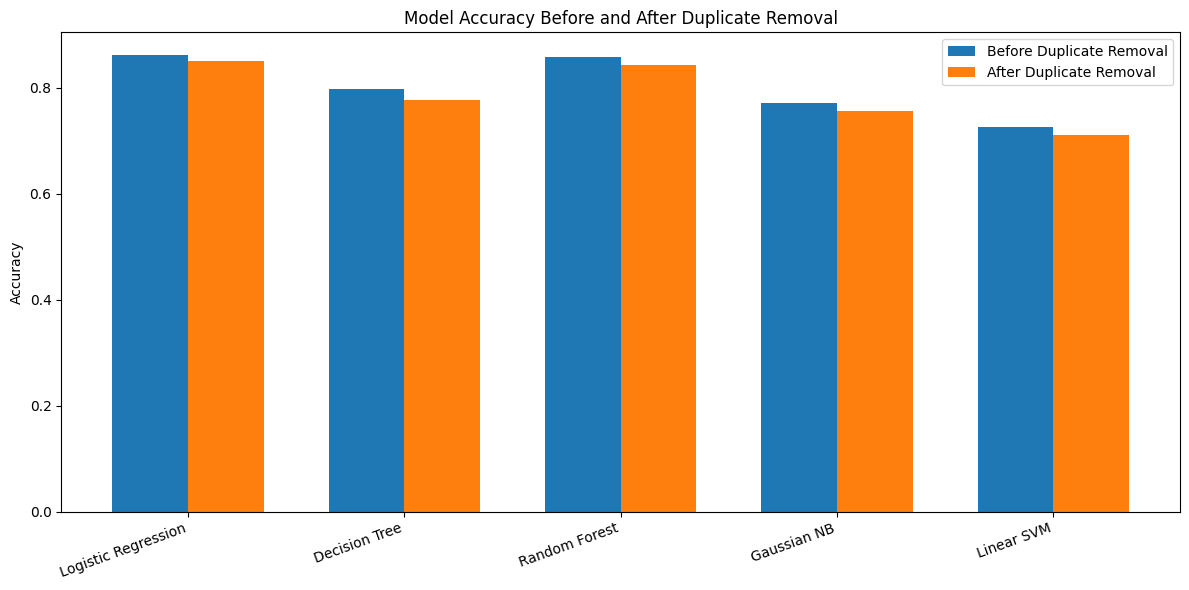

In [21]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Gaussian NB",
    "Linear SVM"
]

accuracy_before = [0.862, 0.798, 0.858, 0.772, 0.727]
accuracy_after = [0.8505, 0.7774, 0.8435, 0.7567, 0.7104]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x - width/2, accuracy_before, width, label="Before Duplicate Removal")
plt.bar(x + width/2, accuracy_after, width, label="After Duplicate Removal")

plt.xticks(x, models, rotation=20, ha="right")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Before and After Duplicate Removal")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd

comparison_metrics = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gaussian Naive Bayes",
        "Linear SVM"
    ],

    "Precision Before": [0.518, 0.284, 0.469, 0.320, 0.308],
    "Precision After": [0.5398, 0.2768, 0.4639, 0.3320, 0.3155],

    "Recall Before": [0.158, 0.296, 0.160, 0.564, 0.769],
    "Recall After": [0.1537, 0.2822, 0.1485, 0.5834, 0.7645],

    "F1 Before": [0.242, 0.290, 0.239, 0.408, 0.440],
    "F1 After": [0.2393, 0.2795, 0.2249, 0.4231, 0.4467]
})

print("CLASS 1 METRICS: BEFORE AND AFTER DUPLICATE REMOVAL")
display(comparison_metrics.round(4))

CLASS 1 METRICS: BEFORE AND AFTER DUPLICATE REMOVAL


,Model,Precision Before,Precision After,Recall Before,Recall After,F1 Before,F1 After
0,Logistic Regression,0.518,0.5398,0.158,0.1537,0.242,0.2393
1,Decision Tree,0.284,0.2768,0.296,0.2822,0.290,0.2795
2,Random Forest,0.469,0.4639,0.160,0.1485,0.239,0.2249
3,Gaussian Naive Bayes,0.320,0.3320,0.564,0.5834,0.408,0.4231
4,Linear SVM,0.308,0.3155,0.769,0.7645,0.440,0.4467


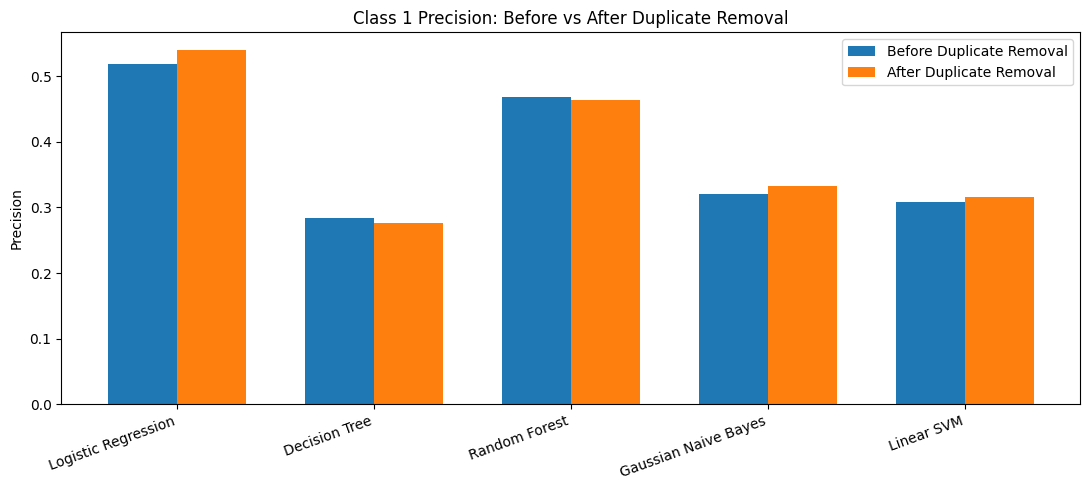

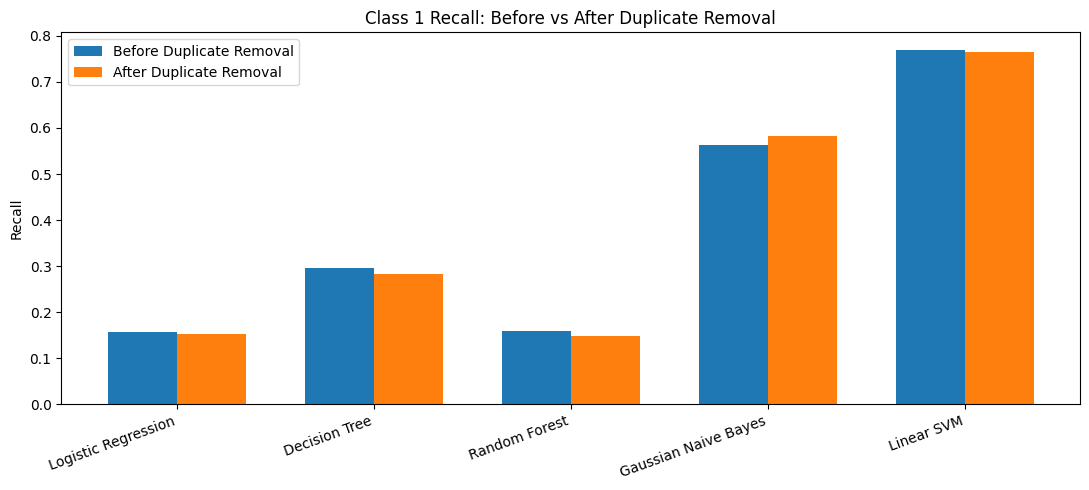

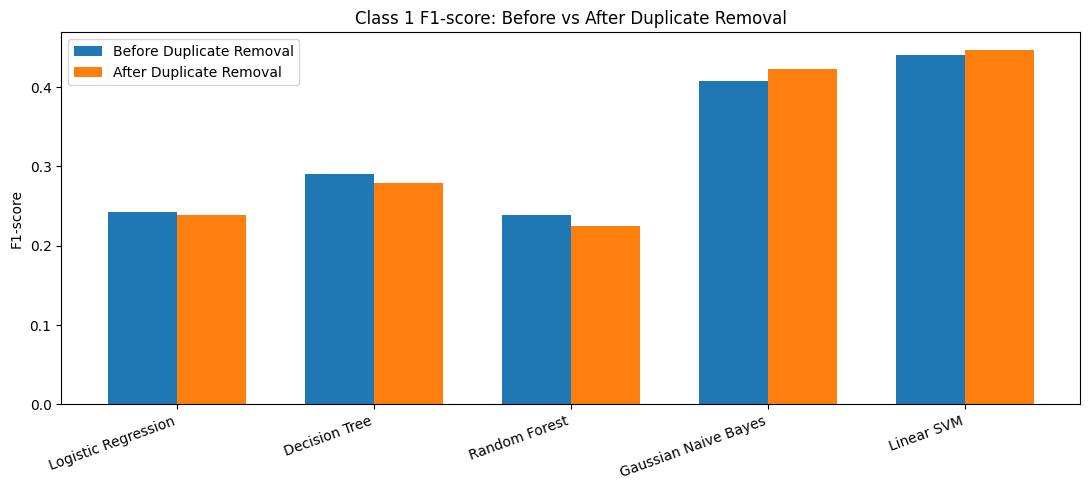

In [23]:
import matplotlib.pyplot as plt
import numpy as np

models = comparison_metrics["Model"]

metrics = [
    ("Precision", "Precision Before", "Precision After"),
    ("Recall", "Recall Before", "Recall After"),
    ("F1-score", "F1 Before", "F1 After")
]

for metric_name, before_col, after_col in metrics:

    x = np.arange(len(models))
    width = 0.35

    plt.figure(figsize=(11, 5))

    plt.bar(
        x - width/2,
        comparison_metrics[before_col],
        width,
        label="Before Duplicate Removal"
    )

    plt.bar(
        x + width/2,
        comparison_metrics[after_col],
        width,
        label="After Duplicate Removal"
    )

    plt.xticks(x, models, rotation=20, ha="right")
    plt.ylabel(metric_name)
    plt.title(f"Class 1 {metric_name}: Before vs After Duplicate Removal")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 11. Overall Experimental Conclusion

This experiment investigated the effect of removing exact duplicate rows from the CDC Diabetes Health Indicators dataset and compared the performance of five machine learning classification algorithms before and after duplicate removal.

The original dataset contained 253,680 records. After removing 24,206 exact duplicate rows, the revised dataset contained 229,474 records.

The comparison showed that accuracy decreased slightly for all five models after duplicate removal. However, the effect on Class 1 precision, recall and F1-score varied across the models.

Gaussian Naive Bayes improved across all three Class 1 metrics, while Linear SVM continued to achieve the highest Class 1 recall and F1-score. Logistic Regression maintained the highest overall accuracy.

The experiment demonstrates that duplicate handling can influence machine learning results and that model evaluation should consider multiple performance metrics rather than accuracy alone.

One limitation is that identical survey responses do not necessarily belong to the same individual. Since participant identifiers were not available for verification, the removal of exact duplicate rows was treated as a separate experimental approach rather than proof that the records were erroneous.

Further work could investigate alternative duplicate-handling methods, cross-validation, hyperparameter tuning and evaluation on an independent dataset.

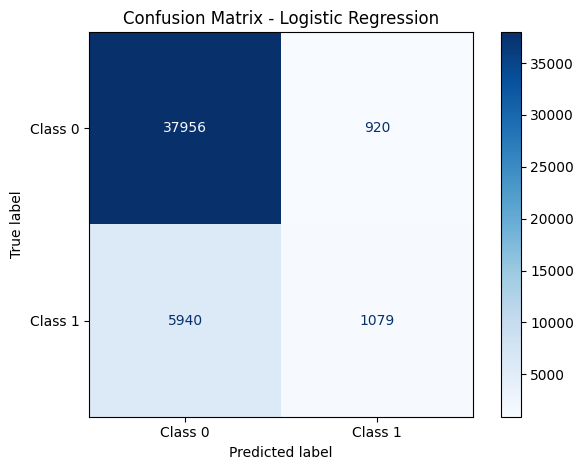

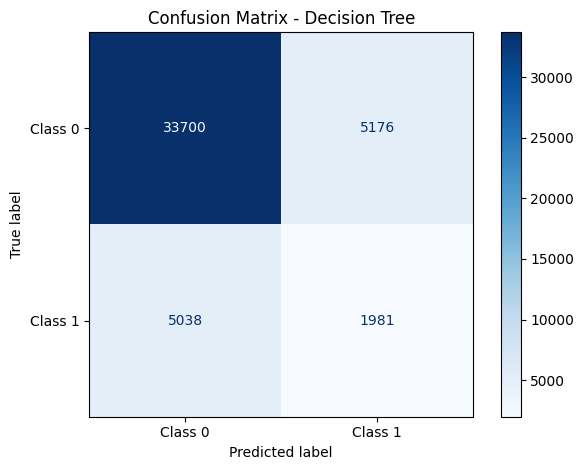

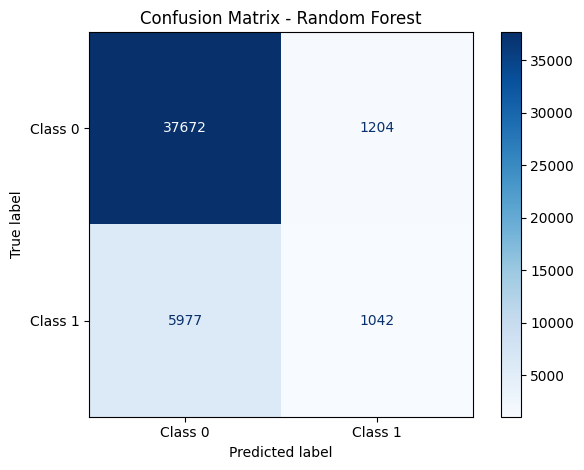

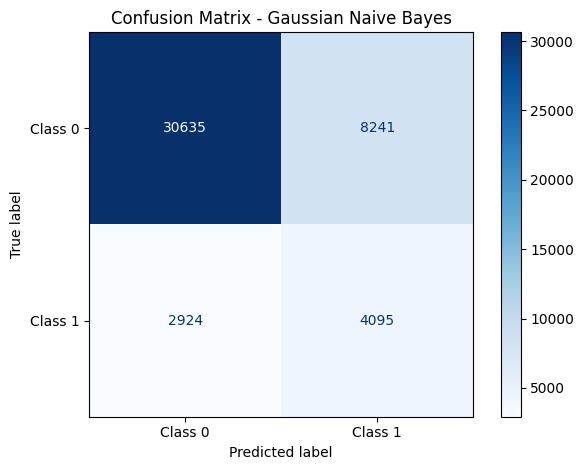

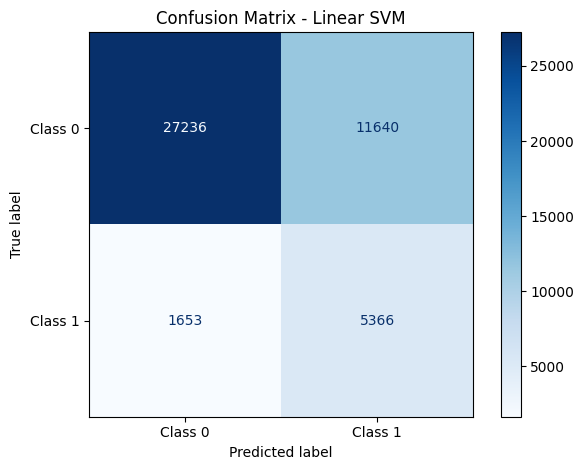

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

model_predictions = {
    "Logistic Regression": (y_test_clean, y_pred_logistic_clean),
    "Decision Tree": (y_test_clean, y_pred_tree_clean),
    "Random Forest": (y_test_clean, y_pred_rf_clean),
    "Gaussian Naive Bayes": (y_test_clean, y_pred_nb_clean),
    "Linear SVM": (y_test_clean, y_pred_svm_clean)
}

for model_name, (actual, predicted) in model_predictions.items():

    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        display_labels=["Class 0", "Class 1"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

## 13. Confusion Matrix Analysis

Confusion matrices were generated to examine the classification performance of the five machine learning models in more detail.

A confusion matrix presents four outcomes:

- **True Negative (TN):** Class 0 correctly predicted as Class 0.
- **True Positive (TP):** Class 1 correctly predicted as Class 1.
- **False Positive (FP):** Class 0 incorrectly predicted as Class 1.
- **False Negative (FN):** Class 1 incorrectly predicted as Class 0.

The confusion matrices help identify the types of classification errors made by each model. In particular, false negatives are important in this experiment because they represent records belonging to the combined prediabetes/diabetes category that the model incorrectly classified as Class 0.

This analysis provides additional insight beyond overall accuracy and supports the comparison of precision, recall and F1-score across the five models.

In [25]:
final_comparison = pd.DataFrame({
    "Model": models,

    "Accuracy Before": [0.862, 0.798, 0.858, 0.772, 0.727],
    "Accuracy After": [0.8505, 0.7774, 0.8435, 0.7567, 0.7104],

    "Precision Before": [0.518, 0.284, 0.469, 0.320, 0.308],
    "Precision After": [0.5398, 0.2768, 0.4639, 0.3320, 0.3155],

    "Recall Before": [0.158, 0.296, 0.160, 0.564, 0.769],
    "Recall After": [0.1537, 0.2822, 0.1485, 0.5834, 0.7645],

    "F1 Before": [0.242, 0.290, 0.239, 0.408, 0.440],
    "F1 After": [0.2393, 0.2795, 0.2249, 0.4231, 0.4467]
})

print("FINAL COMPARATIVE ANALYSIS")
display(final_comparison.round(4))

FINAL COMPARATIVE ANALYSIS


,Model,Accuracy Before,Accuracy After,Precision Before,Precision After,Recall Before,Recall After,F1 Before,F1 After
0,Logistic Regression,0.862,0.8505,0.518,0.5398,0.158,0.1537,0.242,0.2393
1,Decision Tree,0.798,0.7774,0.284,0.2768,0.296,0.2822,0.290,0.2795
2,Random Forest,0.858,0.8435,0.469,0.4639,0.160,0.1485,0.239,0.2249
3,Gaussian Naive Bayes,0.772,0.7567,0.320,0.3320,0.564,0.5834,0.408,0.4231
4,Linear SVM,0.727,0.7104,0.308,0.3155,0.769,0.7645,0.440,0.4467


In [26]:
final_comparison.to_csv(
    "CDC_Diabetes_Before_After_Comparison.csv",
    index=False
)

print("Comparison table saved successfully!")

Comparison table saved successfully!


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create Logistic Regression model
logistic_model_controlled = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using unscaled features
logistic_model_controlled.fit(X_train_clean, y_train_clean)

# Make predictions
y_pred_logistic_controlled = logistic_model_controlled.predict(X_test_clean)

# Evaluate the model
print("LOGISTIC REGRESSION - CONTROLLED EXPERIMENT")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_logistic_controlled))
print(classification_report(y_test_clean, y_pred_logistic_controlled))

LOGISTIC REGRESSION - CONTROLLED EXPERIMENT
Accuracy: 0.850397646802484
              precision    recall  f1-score   support

           0       0.86      0.98      0.92     38876
           1       0.54      0.15      0.24      7019

    accuracy                           0.85     45895
   macro avg       0.70      0.56      0.58     45895
weighted avg       0.81      0.85      0.81     45895



In [28]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Decision Tree model
tree_model_controlled = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

# Train the model
tree_model_controlled.fit(X_train_clean, y_train_clean)

# Make predictions
y_pred_tree_controlled = tree_model_controlled.predict(X_test_clean)

# Evaluate the model
print("DECISION TREE - CONTROLLED EXPERIMENT")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_tree_controlled))
print(classification_report(y_test_clean, y_pred_tree_controlled))

DECISION TREE - CONTROLLED EXPERIMENT
Accuracy: 0.7774485238043359
              precision    recall  f1-score   support

           0       0.87      0.87      0.87     38876
           1       0.28      0.28      0.28      7019

    accuracy                           0.78     45895
   macro avg       0.57      0.57      0.57     45895
weighted avg       0.78      0.78      0.78     45895



In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Random Forest model
rf_model_controlled = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the model
rf_model_controlled.fit(X_train_clean, y_train_clean)

# Make predictions
y_pred_rf_controlled = rf_model_controlled.predict(X_test_clean)

# Evaluate the model
print("RANDOM FOREST - CONTROLLED EXPERIMENT")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_rf_controlled))
print(classification_report(y_test_clean, y_pred_rf_controlled))

RANDOM FOREST - CONTROLLED EXPERIMENT
Accuracy: 0.8435341540472818
              precision    recall  f1-score   support

           0       0.86      0.97      0.91     38876
           1       0.46      0.15      0.22      7019

    accuracy                           0.84     45895
   macro avg       0.66      0.56      0.57     45895
weighted avg       0.80      0.84      0.81     45895



In [30]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Create Gaussian Naive Bayes model
nb_model_controlled = GaussianNB()

# Train the model
nb_model_controlled.fit(X_train_clean, y_train_clean)

# Make predictions
y_pred_nb_controlled = nb_model_controlled.predict(X_test_clean)

# Evaluate the model
print("GAUSSIAN NAIVE BAYES - CONTROLLED EXPERIMENT")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_nb_controlled))
print(classification_report(y_test_clean, y_pred_nb_controlled))

GAUSSIAN NAIVE BAYES - CONTROLLED EXPERIMENT
Accuracy: 0.7567273123433925
              precision    recall  f1-score   support

           0       0.91      0.79      0.85     38876
           1       0.33      0.58      0.42      7019

    accuracy                           0.76     45895
   macro avg       0.62      0.69      0.63     45895
weighted avg       0.82      0.76      0.78     45895



In [31]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create Linear SVM model
svm_model_controlled = LinearSVC(
    class_weight='balanced',
    random_state=42,
    max_iter=2000
)

# Train the model using unscaled features
svm_model_controlled.fit(X_train_clean, y_train_clean)

# Make predictions
y_pred_svm_controlled = svm_model_controlled.predict(X_test_clean)

# Evaluate the model
print("LINEAR SVM - CONTROLLED EXPERIMENT")
print("Accuracy:", accuracy_score(y_test_clean, y_pred_svm_controlled))
print(classification_report(y_test_clean, y_pred_svm_controlled))

LINEAR SVM - CONTROLLED EXPERIMENT
Accuracy: 0.7103606057304718
              precision    recall  f1-score   support

           0       0.94      0.70      0.80     38876
           1       0.32      0.76      0.45      7019

    accuracy                           0.71     45895
   macro avg       0.63      0.73      0.63     45895
weighted avg       0.85      0.71      0.75     45895



In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

controlled_results = []

models_controlled = {
    "Logistic Regression": y_pred_logistic_controlled,
    "Decision Tree": y_pred_tree_controlled,
    "Random Forest": y_pred_rf_controlled,
    "Gaussian Naive Bayes": y_pred_nb_controlled,
    "Linear SVM": y_pred_svm_controlled
}

for model_name, predictions in models_controlled.items():
    controlled_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_clean, predictions),
        "Class 1 Precision": precision_score(y_test_clean, predictions, pos_label=1),
        "Class 1 Recall": recall_score(y_test_clean, predictions, pos_label=1),
        "Class 1 F1": f1_score(y_test_clean, predictions, pos_label=1)
    })

controlled_comparison = pd.DataFrame(controlled_results)

print("FINAL CONTROLLED EXPERIMENT RESULTS")
display(controlled_comparison.round(4))

FINAL CONTROLLED EXPERIMENT RESULTS


,Model,Accuracy,Class 1 Precision,Class 1 Recall,Class 1 F1
0,Logistic Regression,0.8504,0.5383,0.1532,0.2385
1,Decision Tree,0.7774,0.2768,0.2822,0.2795
2,Random Forest,0.8435,0.4639,0.1485,0.2249
3,Gaussian Naive Bayes,0.7567,0.3320,0.5834,0.4231
4,Linear SVM,0.7104,0.3155,0.7645,0.4467


In [33]:
# Original experiment results (as recorded in your original notebook)
original_results = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gaussian Naive Bayes",
        "Linear SVM"
    ],
    "Accuracy Before": [0.8622, 0.7977, 0.8577, 0.7722, 0.7275],
    "Precision Before": [0.518, 0.284, 0.469, 0.320, 0.308],
    "Recall Before": [0.158, 0.296, 0.160, 0.564, 0.769],
    "F1 Before": [0.242, 0.290, 0.239, 0.408, 0.440]
}

before_df = pd.DataFrame(original_results)

# Rename controlled experiment columns
after_df = controlled_comparison.rename(columns={
    "Accuracy": "Accuracy After",
    "Class 1 Precision": "Precision After",
    "Class 1 Recall": "Recall After",
    "Class 1 F1": "F1 After"
})

# Combine original and controlled results
final_controlled_comparison = before_df.merge(
    after_df,
    on="Model"
)

# Arrange columns
final_controlled_comparison = final_controlled_comparison[
    [
        "Model",
        "Accuracy Before", "Accuracy After",
        "Precision Before", "Precision After",
        "Recall Before", "Recall After",
        "F1 Before", "F1 After"
    ]
]

print("FINAL BEFORE-AND-AFTER COMPARISON")
display(final_controlled_comparison.round(4))

FINAL BEFORE-AND-AFTER COMPARISON


,Model,Accuracy Before,Accuracy After,Precision Before,Precision After,Recall Before,Recall After,F1 Before,F1 After
0,Logistic Regression,0.8622,0.8504,0.518,0.5383,0.158,0.1532,0.242,0.2385
1,Decision Tree,0.7977,0.7774,0.284,0.2768,0.296,0.2822,0.290,0.2795
2,Random Forest,0.8577,0.8435,0.469,0.4639,0.160,0.1485,0.239,0.2249
3,Gaussian Naive Bayes,0.7722,0.7567,0.320,0.3320,0.564,0.5834,0.408,0.4231
4,Linear SVM,0.7275,0.7104,0.308,0.3155,0.769,0.7645,0.440,0.4467


### Comparative Analysis of Original and Duplicate-Removed Experiments

The results of the original experiment and the duplicate-removed experiment were compared using accuracy, precision, recall and F1-score for all five machine learning models.

After removing 24,206 exact duplicate rows, the dataset size decreased from 253,680 to 229,474 records. The comparison showed that accuracy decreased slightly for all five models. However, the changes in precision, recall and F1-score were different across the models.

Logistic Regression and Random Forest showed small decreases in their Class 1 recall and F1-scores. Decision Tree also showed a slight decrease across all four evaluation metrics. In contrast, Gaussian Naive Bayes showed improvements in Class 1 precision, recall and F1-score, although its accuracy decreased. Linear SVM continued to achieve the highest Class 1 recall and F1-score among the five models after duplicate removal.

These findings indicate that removing exact duplicate rows does not necessarily improve the performance of every machine learning model. The effect varies depending on the algorithm and evaluation metric.

It is also important to note that identical survey responses do not necessarily belong to the same individual. Since participant identifiers were not available in this dataset, it was not possible to establish whether all repeated rows represented duplicate participants or different individuals with identical responses. Therefore, this experiment examines the effect of an exact duplicate-removal approach rather than proving that all removed records were erroneous.

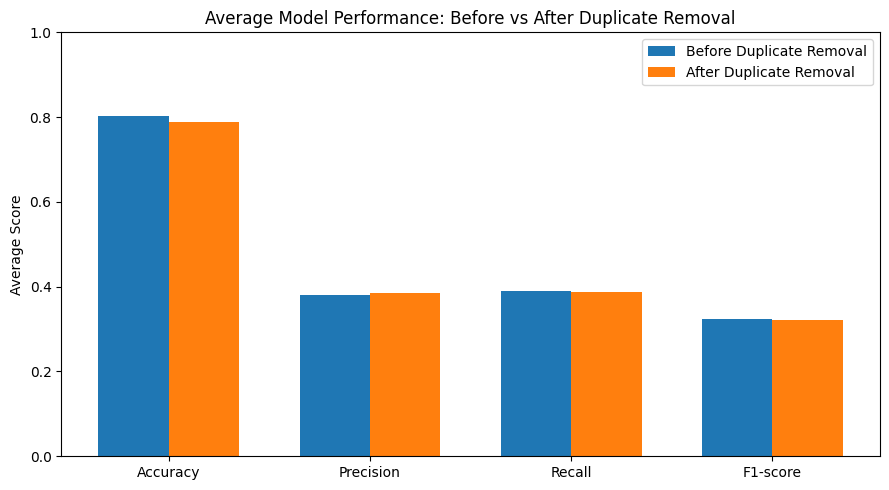

In [34]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

before_values = [
    final_controlled_comparison["Accuracy Before"].mean(),
    final_controlled_comparison["Precision Before"].mean(),
    final_controlled_comparison["Recall Before"].mean(),
    final_controlled_comparison["F1 Before"].mean()
]

after_values = [
    final_controlled_comparison["Accuracy After"].mean(),
    final_controlled_comparison["Precision After"].mean(),
    final_controlled_comparison["Recall After"].mean(),
    final_controlled_comparison["F1 After"].mean()
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, before_values, width, label="Before Duplicate Removal")
plt.bar(x + width/2, after_values, width, label="After Duplicate Removal")

plt.xticks(x, metrics)
plt.ylabel("Average Score")
plt.title("Average Model Performance: Before vs After Duplicate Removal")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
final_controlled_comparison.to_csv(
    "CDC_Diabetes_Final_Controlled_Comparison.csv",
    index=False
)

print("Final comparison table saved successfully.")

Final comparison table saved successfully.


### Final Conclusion

This supplementary experiment examined the effect of removing exact duplicate rows from the CDC Diabetes Health Indicators dataset. The original dataset contained 253,680 records, which decreased to 229,474 after removing 24,206 exact duplicate rows.

Five classification algorithms were evaluated before and after duplicate removal. The results showed that accuracy decreased slightly for all five models, while precision, recall and F1-score changed differently depending on the algorithm.

Gaussian Naive Bayes showed improvement in all three Class 1 metrics after duplicate removal. Linear SVM achieved the highest Class 1 recall and F1-score in the duplicate-removed experiment. These results demonstrate that data preprocessing choices can influence the performance of machine learning models.

However, identical survey responses do not necessarily represent the same participant. Since unique participant identifiers were unavailable, it was not possible to confirm whether the repeated records belonged to the same individuals. Therefore, duplicate removal should be considered an experimental data-handling approach rather than an automatic correction.

Future work can include testing alternative duplicate-handling strategies, cross-validation, hyperparameter tuning and evaluation on independent data.